<a href="https://colab.research.google.com/github/tofighi/tutorials/blob/master/ML/Module2_Class_Activity_Solution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Module 2 — Class Activity Solution: End-to-End Machine Learning Pipeline

> 📢 **Note**: **No submission is necessary.** This is the complete reference solution notebook with all code fully executed and verified.

---

## Part A: Classification Pipeline (Wine Type Prediction)

### Step A1: Data Loading & Combination


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# 1. Load Red Wine data
url_red = "https://raw.githubusercontent.com/tofighi/MachineLearning/master/datasets/winequality-red.csv"
red_df = pd.read_csv(url_red, sep=";")
red_df['color'] = 0  # 0 for Red

# 2. Load White Wine data
url_white = "https://github.com/tofighi/MachineLearning/raw/master/datasets/white-wine.csv"
white_df = pd.read_csv(url_white)
white_df['color'] = 1  # 1 for White

# 3. Combine DataFrames
df_wine = pd.concat([red_df, white_df], ignore_index=True)
print(f"Combined Wine Dataset Shape: {df_wine.shape}")
df_wine.head()


Combined Wine Dataset Shape: (6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0


### Step A2: Exploratory Data Analysis (EDA)


--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  color                 6497 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 660.0 KB

--- Feature Summary ---
       fixed acidity  volatil

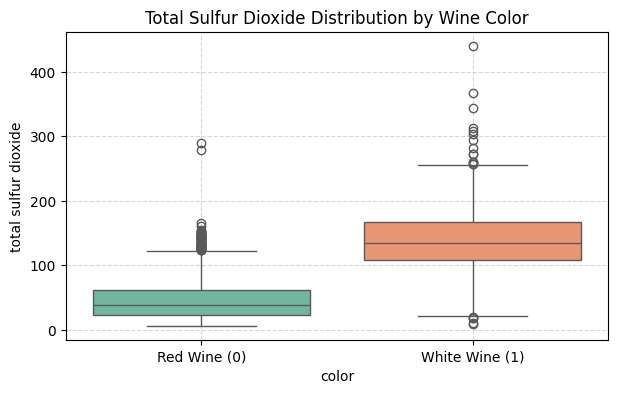

In [2]:
print("--- Dataset Info ---")
df_wine.info()

print("\n--- Feature Summary ---")
print(df_wine.describe())

# Boxplot visualization
plt.figure(figsize=(7, 4))
sns.boxplot(x='color', y='total sulfur dioxide', data=df_wine, palette='Set2')
plt.xticks([0, 1], ['Red Wine (0)', 'White Wine (1)'])
plt.title('Total Sulfur Dioxide Distribution by Wine Color')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


### Step A3: Feature Matrix ($X$) & Target ($y$) Separation


In [3]:
X_wine = df_wine.drop(['color', 'quality'], axis=1)
y_wine = df_wine['color']

print(f"X shape: {X_wine.shape} | y shape: {y_wine.shape}")


X shape: (6497, 11) | y shape: (6497,)


### Step A4: Train/Test Split


In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_wine, y_wine, test_size=0.20, random_state=42)
print(f"X_train shape: {X_train.shape} | X_test shape: {X_test.shape}")


X_train shape: (5197, 11) | X_test shape: (1300, 11)


### Step A5: Classification & Evaluation


In [5]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)
acc = accuracy_score(y_test, y_pred)

print(f"Unscaled k-NN Accuracy: {acc:.4f}\n")
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Unscaled k-NN Accuracy: 0.9423

Confusion Matrix:
[[289  52]
 [ 23 936]]

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.85      0.89       341
           1       0.95      0.98      0.96       959

    accuracy                           0.94      1300
   macro avg       0.94      0.91      0.92      1300
weighted avg       0.94      0.94      0.94      1300



### Step A6: Hyperparameter Tuning with `GridSearchCV`


In [6]:
from sklearn.model_selection import GridSearchCV

param_grid = {'n_neighbors': [3, 5, 7, 9, 11]}
knn_cv = GridSearchCV(KNeighborsClassifier(), param_grid, cv=5, scoring='accuracy')
knn_cv.fit(X_train, y_train)

print(f"Optimal n_neighbors: {knn_cv.best_params_['n_neighbors']}")
print(f"Best 5-Fold CV Accuracy: {knn_cv.best_score_:.4f}")


Optimal n_neighbors: 11
Best 5-Fold CV Accuracy: 0.9430


### Step A7: Scaling via `scikit-learn` Pipeline


In [7]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

scaled_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=knn_cv.best_params_['n_neighbors']))
])

scaled_pipe.fit(X_train, y_train)
pipe_acc = scaled_pipe.score(X_test, y_test)

print(f"Test Accuracy WITHOUT Scaling: {acc:.4f}")
print(f"Test Accuracy WITH Scaling:    {pipe_acc:.4f}")


Test Accuracy WITHOUT Scaling: 0.9423
Test Accuracy WITH Scaling:    0.9900


---
## Part B: Regression Pipeline (Life Expectancy Prediction)

### Step B1: Data Loading & Preprocessing


In [8]:
url_gap = 'https://raw.githubusercontent.com/tofighi/MachineLearning/master/datasets/gapminder.csv'
df_gap = pd.read_csv(url_gap)

# Drop non-numeric 'Region' column
df_gap_num = df_gap.drop('Region', axis=1)
df_gap_num.head()


,population,fertility,HIV,CO2,BMI_male,GDP,BMI_female,life,child_mortality
0,34811059.0,2.73,0.1,3.328945,24.59620,12314.0,129.9049,75.3,29.5
1,19842251.0,6.43,2.0,1.474353,22.25083,7103.0,130.1247,58.3,192.0
2,40381860.0,2.24,0.5,4.785170,27.50170,14646.0,118.8915,75.5,15.4
3,2975029.0,1.40,0.1,1.804106,25.35542,7383.0,132.8108,72.5,20.0
4,21370348.0,1.96,0.1,18.016313,27.56373,41312.0,117.3755,81.5,5.2


### Step B2: Feature & Target Split, Train/Test Split


In [9]:
X_gap = df_gap_num.drop('life', axis=1)
y_gap = df_gap_num['life']

X_train_g, X_test_g, y_train_g, y_test_g = train_test_split(X_gap, y_gap, test_size=0.30, random_state=42)
print(f"Train set: {X_train_g.shape} | Test set: {X_test_g.shape}")


Train set: (97, 8) | Test set: (42, 8)


### Step B3: Model Training & Regression Metrics


In [10]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

reg = LinearRegression()
reg.fit(X_train_g, y_train_g)

y_pred_g = reg.predict(X_test_g)

print("Linear Regression Metrics on Test Set:")
print(f"R² Score: {r2_score(y_test_g, y_pred_g):.4f}")
print(f"MAE:      {mean_absolute_error(y_test_g, y_pred_g):.4f}")
print(f"RMSE:     {np.sqrt(mean_squared_error(y_test_g, y_pred_g)):.4f}")


Linear Regression Metrics on Test Set:
R² Score: 0.8380
MAE:      2.3625
RMSE:     3.2476


### Step B4: Cross-Validation & Ridge Regularization


In [11]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_val_score

# 1. 5-Fold Cross-Validation on Linear Regression
cv_scores = cross_val_score(LinearRegression(), X_gap, y_gap, cv=5, scoring='r2')
print(f"5-Fold CV Mean R²: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

# 2. GridSearchCV on Ridge Regression
alpha_space = np.logspace(-4, 0, 50)
ridge_cv = GridSearchCV(Ridge(), {'alpha': alpha_space}, cv=10, scoring='r2')
ridge_cv.fit(X_gap, y_gap)

best_alpha = ridge_cv.best_params_['alpha']
print(f"Optimal Ridge Alpha: {best_alpha:.6f}")
print(f"Best 10-Fold CV R²:  {ridge_cv.best_score_:.4f}")


5-Fold CV Mean R²: 0.8600 ± 0.0541
Optimal Ridge Alpha: 1.000000
Best 10-Fold CV R²:  0.8437


### Step B5: Complete Scaled Regression Pipeline


In [12]:
from sklearn.pipeline import Pipeline

scaled_ridge_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('ridge', Ridge(alpha=best_alpha))
])

scaled_ridge_pipe.fit(X_train_g, y_train_g)
y_pred_pipe = scaled_ridge_pipe.predict(X_test_g)

print("Scaled Ridge Pipeline Test Performance:")
print(f"Test R² Score: {r2_score(y_test_g, y_pred_pipe):.4f}")
print(f"Test MAE:      {mean_absolute_error(y_test_g, y_pred_pipe):.4f}")
print(f"Test RMSE:     {np.sqrt(mean_squared_error(y_test_g, y_pred_pipe)):.4f}")


Scaled Ridge Pipeline Test Performance:
Test R² Score: 0.8386
Test MAE:      2.3706
Test RMSE:     3.2416
